In [1]:
# =====================================
# CNN1D ONLY TIMESERIES EXPERIMENT
# =====================================

import pandas as pd
import matplotlib.pyplot as plt
import torch

from src.run.model.run_cnn_timeseries_classifier import RunTimeSeriesCNN
from src.run.preprocess.config import _project_path

In [2]:
# =====================================
# EPOCHS EXPERIMENT
# =====================================

results = []

epochs_values = [25, 50, 75, 100, 150, 200]

for epochs in epochs_values:

    print(f"\n=== Running experiment with epochs={epochs} ===")

    runner = RunTimeSeriesCNN(
        data_root=_project_path("PaHaW/PaHaW/PaHaW_public"),
        metadata_path=_project_path(
            "PaHaW/PaHaW/PaHaW_files/corpus_PaHaW.xlsx"
        ),
        tasks=[4, 8],
        feature_names=("x", "y"),
        engineered_features=("speed", "pressure_derivative"),

        batch_size=16,

        # Iperparametro sotto test
        epochs=epochs,

        learning_rate=1e-3,
        regularization=1e-6,
        n_splits=5,

        normalize=True,
        seed=42,

        device=(
            "cuda"
            if torch.cuda.is_available()
            else "cpu"
        ),

        output_dir=_project_path(
            "experiments/test_iperparametri/cnn1D(timeseries)/"
            f"epochs/epochs_{epochs}"
        ),

        training_cfg={
            "metrics": [
                "accuracy",
                "f1",
                "auc",
                "precision",
                "recall",
                "specificity",
            ],

            "monitor_metric": "auc",

            "early_stopping_patience": float("inf"),
            "min_delta": 0.0,

            "results_writer": "csv",
            "save_metrics": True,
        },
    )

    summary = runner.run()

    averages = summary["averages"]

    # =====================================
    # SAVE RESULTS
    # =====================================

    results.append({
        "epochs": epochs,

        "accuracy": averages["val_accuracy"],
        "f1": averages["val_f1"],
        "auc": averages["val_auc"],
        "precision": averages["val_precision"],
        "recall": averages["val_recall"],
        "specificity": averages["val_specificity"],
    })

    # =====================================
    # PRINT RESULTS
    # =====================================

    print(f"\n=== Results for epochs={epochs} ===")

    print(f"Accuracy:    {averages['val_accuracy']:.4f}")
    print(f"F1 Score:    {averages['val_f1']:.4f}")
    print(f"AUC:         {averages['val_auc']:.4f}")
    print(f"Precision:   {averages['val_precision']:.4f}")
    print(f"Recall:      {averages['val_recall']:.4f}")
    print(f"Specificity: {averages['val_specificity']:.4f}")


# =====================================
# RESULTS DATAFRAME
# =====================================

df_epochs = pd.DataFrame(results)

print("\n=== EPOCHS EXPERIMENT RESULTS ===")

display(
    df_epochs.sort_values(
        by="auc",
        ascending=False
    )
)


=== Running experiment with epochs=25 ===
[WARNING] Mismatch in 00075__8_1.svc: expected 1663, found 1646.
Fold 01 | Epoch 01 | train_loss=0.7138 | val_loss=0.6747 | train_accuracy=0.4750 | val_accuracy=0.5333
Fold 01 | Epoch 02 | train_loss=0.6717 | val_loss=0.6676 | train_accuracy=0.6167 | val_accuracy=0.6000
Fold 01 | Epoch 03 | train_loss=0.6549 | val_loss=0.6668 | train_accuracy=0.6083 | val_accuracy=0.6333
Fold 01 | Epoch 04 | train_loss=0.6313 | val_loss=0.7171 | train_accuracy=0.6250 | val_accuracy=0.6333
Fold 01 | Epoch 05 | train_loss=0.6261 | val_loss=0.7183 | train_accuracy=0.6750 | val_accuracy=0.6333
Fold 01 | Epoch 06 | train_loss=0.6349 | val_loss=0.6705 | train_accuracy=0.6417 | val_accuracy=0.6333
Fold 01 | Epoch 07 | train_loss=0.6390 | val_loss=0.6661 | train_accuracy=0.6167 | val_accuracy=0.6333
Fold 01 | Epoch 08 | train_loss=0.6442 | val_loss=0.6893 | train_accuracy=0.6750 | val_accuracy=0.6333
Fold 01 | Epoch 09 | train_loss=0.6369 | val_loss=0.7000 | train_acc

,epochs,accuracy,f1,auc,precision,recall,specificity
5,200,0.653333,0.667562,0.766071,0.665653,0.710714,0.589286
4,150,0.580000,0.687330,0.750000,0.542645,0.942857,0.216071
2,75,0.586667,0.685685,0.720536,0.551948,0.914286,0.260714
3,100,0.600000,0.614427,0.713393,0.559482,0.744643,0.439286
1,50,0.580000,0.668227,0.686607,0.544301,0.871429,0.280357
0,25,0.566667,0.669033,0.680357,0.541519,0.887500,0.248214


In [3]:
# =====================================
# LEARNING RATE EXPERIMENT
# =====================================

results = []

learning_rates = [1e-2, 1e-3, 1e-4, 1e-5, 1e-6]

for lr in learning_rates:

    print(f"\n=== Running experiment with learning_rate={lr} ===")

    runner = RunTimeSeriesCNN(
        data_root=_project_path("PaHaW/PaHaW/PaHaW_public"),
        metadata_path=_project_path(
            "PaHaW/PaHaW/PaHaW_files/corpus_PaHaW.xlsx"
        ),
        tasks=[4, 8],
        feature_names=("x", "y"),
        engineered_features=("speed", "pressure_derivative"),

        batch_size=16,

        epochs=200,

        # Iperparametro sotto test
        learning_rate=lr,

        regularization=1e-6,
        n_splits=5,

        normalize=True,
        seed=42,

        device=(
            "cuda"
            if torch.cuda.is_available()
            else "cpu"
        ),

        output_dir=_project_path(
            "experiments/test_iperparametri/cnn1D(timeseries)/"
            f"learning_rate/lr_{lr}"
        ),

        training_cfg={
            "metrics": [
                "accuracy",
                "f1",
                "auc",
                "precision",
                "recall",
                "specificity",
            ],

            "monitor_metric": "auc",

            "early_stopping_patience": float("inf"),
            "min_delta": 0.0,

            "results_writer": "csv",
            "save_metrics": True,
        },
    )

    summary = runner.run()

    averages = summary["averages"]

    # =====================================
    # SAVE RESULTS
    # =====================================

    results.append({
        "learning_rate": lr,

        "accuracy": averages["val_accuracy"],
        "f1": averages["val_f1"],
        "auc": averages["val_auc"],
        "precision": averages["val_precision"],
        "recall": averages["val_recall"],
        "specificity": averages["val_specificity"],
    })

    # =====================================
    # PRINT RESULTS
    # =====================================

    print(f"\n=== Results for learning_rate={lr} ===")

    print(f"Accuracy:    {averages['val_accuracy']:.4f}")
    print(f"F1 Score:    {averages['val_f1']:.4f}")
    print(f"AUC:         {averages['val_auc']:.4f}")
    print(f"Precision:   {averages['val_precision']:.4f}")
    print(f"Recall:      {averages['val_recall']:.4f}")
    print(f"Specificity: {averages['val_specificity']:.4f}")


# =====================================
# RESULTS DATAFRAME
# =====================================

df_lr = pd.DataFrame(results)

print("\n=== LEARNING RATE EXPERIMENT RESULTS ===")

display(
    df_lr.sort_values(
        by="auc",
        ascending=False
    )
)


=== Running experiment with learning_rate=0.01 ===
[WARNING] Mismatch in 00075__8_1.svc: expected 1663, found 1646.
Fold 01 | Epoch 01 | train_loss=0.7947 | val_loss=0.7097 | train_accuracy=0.4500 | val_accuracy=0.4667
Fold 01 | Epoch 02 | train_loss=0.7146 | val_loss=0.7115 | train_accuracy=0.5250 | val_accuracy=0.4667
Fold 01 | Epoch 03 | train_loss=0.6885 | val_loss=0.6884 | train_accuracy=0.5083 | val_accuracy=0.5667
Fold 01 | Epoch 04 | train_loss=0.6899 | val_loss=0.6964 | train_accuracy=0.5417 | val_accuracy=0.4333
Fold 01 | Epoch 05 | train_loss=0.6825 | val_loss=0.6885 | train_accuracy=0.4917 | val_accuracy=0.5000
Fold 01 | Epoch 06 | train_loss=0.6691 | val_loss=0.6685 | train_accuracy=0.5917 | val_accuracy=0.6000
Fold 01 | Epoch 07 | train_loss=0.6499 | val_loss=0.6833 | train_accuracy=0.6333 | val_accuracy=0.6000
Fold 01 | Epoch 08 | train_loss=0.6757 | val_loss=0.6877 | train_accuracy=0.5417 | val_accuracy=0.5333
Fold 01 | Epoch 09 | train_loss=0.6328 | val_loss=0.6879 | 

,learning_rate,accuracy,f1,auc,precision,recall,specificity
1,0.001000,0.653333,0.667562,0.766071,0.665653,0.710714,0.589286
0,0.010000,0.586667,0.692544,0.747321,0.551511,0.942857,0.241071
2,0.000100,0.620000,0.663866,0.708929,0.589108,0.776786,0.451786
3,0.000010,0.600000,0.542454,0.666964,0.465436,0.651786,0.533929
4,0.000001,0.533333,0.322424,0.627679,0.326084,0.346429,0.703571


In [4]:
# =====================================
# REGULARIZATION EXPERIMENT
# =====================================

results = []

regularizations = [1e-3, 1e-4, 1e-5, 1e-6]

for regularization in regularizations:

    print(
        f"\n=== Running experiment with regularization={regularization} ==="
    )

    runner = RunTimeSeriesCNN(
        data_root=_project_path("PaHaW/PaHaW/PaHaW_public"),
        metadata_path=_project_path(
            "PaHaW/PaHaW/PaHaW_files/corpus_PaHaW.xlsx"
        ),
        tasks=[4, 8],
        feature_names=("x", "y"),
        engineered_features=("speed", "pressure_derivative"),

        batch_size=16,

        epochs=200,

        learning_rate=1e-3,

        # Iperparametro sotto test
        regularization=regularization,

        n_splits=5,

        normalize=True,
        seed=42,

        device=(
            "cuda"
            if torch.cuda.is_available()
            else "cpu"
        ),

        output_dir=_project_path(
            "experiments/test_iperparametri/cnn1D(timeseries)/"
            f"regularization/reg_{regularization}"
        ),

        training_cfg={
            "metrics": [
                "accuracy",
                "f1",
                "auc",
                "precision",
                "recall",
                "specificity",
            ],

            "monitor_metric": "auc",

            "early_stopping_patience": float("inf"),
            "min_delta": 0.0,

            "results_writer": "csv",
            "save_metrics": True,
        },
    )

    summary = runner.run()

    averages = summary["averages"]

    # =====================================
    # SAVE RESULTS
    # =====================================

    results.append({
        "regularization": regularization,

        "accuracy": averages["val_accuracy"],
        "f1": averages["val_f1"],
        "auc": averages["val_auc"],
        "precision": averages["val_precision"],
        "recall": averages["val_recall"],
        "specificity": averages["val_specificity"],
    })

    # =====================================
    # PRINT RESULTS
    # =====================================

    print(
        f"\n=== Results for regularization={regularization} ==="
    )

    print(f"Accuracy:    {averages['val_accuracy']:.4f}")
    print(f"F1 Score:    {averages['val_f1']:.4f}")
    print(f"AUC:         {averages['val_auc']:.4f}")
    print(f"Precision:   {averages['val_precision']:.4f}")
    print(f"Recall:      {averages['val_recall']:.4f}")
    print(f"Specificity: {averages['val_specificity']:.4f}")


# =====================================
# RESULTS DATAFRAME
# =====================================

df_reg = pd.DataFrame(results)

print("\n=== REGULARIZATION EXPERIMENT RESULTS ===")

display(
    df_reg.sort_values(
        by="auc",
        ascending=False
    )
)


=== Running experiment with regularization=0.001 ===
[WARNING] Mismatch in 00075__8_1.svc: expected 1663, found 1646.
Fold 01 | Epoch 01 | train_loss=0.7138 | val_loss=0.6750 | train_accuracy=0.4667 | val_accuracy=0.5333
Fold 01 | Epoch 02 | train_loss=0.6714 | val_loss=0.6665 | train_accuracy=0.6250 | val_accuracy=0.6000
Fold 01 | Epoch 03 | train_loss=0.6558 | val_loss=0.6662 | train_accuracy=0.6083 | val_accuracy=0.6333
Fold 01 | Epoch 04 | train_loss=0.6302 | val_loss=0.7165 | train_accuracy=0.6417 | val_accuracy=0.6333
Fold 01 | Epoch 05 | train_loss=0.6320 | val_loss=0.7390 | train_accuracy=0.6667 | val_accuracy=0.6333
Fold 01 | Epoch 06 | train_loss=0.6407 | val_loss=0.6769 | train_accuracy=0.6167 | val_accuracy=0.6333
Fold 01 | Epoch 07 | train_loss=0.6331 | val_loss=0.6637 | train_accuracy=0.6250 | val_accuracy=0.6333
Fold 01 | Epoch 08 | train_loss=0.6406 | val_loss=0.6759 | train_accuracy=0.6667 | val_accuracy=0.6333
Fold 01 | Epoch 09 | train_loss=0.6366 | val_loss=0.6729 

,regularization,accuracy,f1,auc,precision,recall,specificity
3,0.000001,0.653333,0.667562,0.766071,0.665653,0.710714,0.589286
0,0.001000,0.626667,0.657098,0.756250,0.622699,0.728571,0.525000
2,0.000010,0.640000,0.670414,0.756250,0.662723,0.741071,0.537500
1,0.000100,0.613333,0.675197,0.753571,0.593565,0.825000,0.407143


In [5]:
# =====================================
# EARLY STOPPING EXPERIMENT
# =====================================

results = []

early_stopping_values = [25, 50, 100, 150, 200]

for patience in early_stopping_values:

    print(
        f"\n=== Running experiment with early_stopping_patience={patience} ==="
    )

    runner = RunTimeSeriesCNN(
        data_root=_project_path("PaHaW/PaHaW/PaHaW_public"),
        metadata_path=_project_path(
            "PaHaW/PaHaW/PaHaW_files/corpus_PaHaW.xlsx"
        ),
        tasks=[4, 8],
        feature_names=("x", "y"),
        engineered_features=("speed", "pressure_derivative"),

        batch_size=16,

        epochs=200,
        learning_rate=1e-3,
        regularization=1e-6,
        n_splits=5,

        normalize=True,
        seed=42,

        device=(
            "cuda"
            if torch.cuda.is_available()
            else "cpu"
        ),

        output_dir=_project_path(
            "experiments/test_iperparametri/cnn1D(timeseries)/"
            f"early_stopping/patience_{patience}"
        ),

        training_cfg={
            "metrics": [
                "accuracy",
                "f1",
                "auc",
                "precision",
                "recall",
                "specificity",
            ],

            "monitor_metric": "auc",

            # Iperparametro sotto test
            "early_stopping_patience": patience,

            "min_delta": 1e-3,

            "results_writer": "csv",
            "save_metrics": True,
        },
    )

    summary = runner.run()

    averages = summary["averages"]

    # =====================================
    # SAVE RESULTS
    # =====================================

    results.append({
        "early_stopping_patience": patience,

        "accuracy": averages["val_accuracy"],
        "f1": averages["val_f1"],
        "auc": averages["val_auc"],
        "precision": averages["val_precision"],
        "recall": averages["val_recall"],
        "specificity": averages["val_specificity"],
    })

    # =====================================
    # PRINT RESULTS
    # =====================================

    print(
        f"\n=== Results for early_stopping_patience={patience} ==="
    )

    print(f"Accuracy:    {averages['val_accuracy']:.4f}")
    print(f"F1 Score:    {averages['val_f1']:.4f}")
    print(f"AUC:         {averages['val_auc']:.4f}")
    print(f"Precision:   {averages['val_precision']:.4f}")
    print(f"Recall:      {averages['val_recall']:.4f}")
    print(f"Specificity: {averages['val_specificity']:.4f}")


# =====================================
# RESULTS DATAFRAME
# =====================================

df_early_stopping = pd.DataFrame(results)

print("\n=== EARLY STOPPING EXPERIMENT RESULTS ===")

display(
    df_early_stopping.sort_values(
        by="auc",
        ascending=False
    )
)


=== Running experiment with early_stopping_patience=25 ===
[WARNING] Mismatch in 00075__8_1.svc: expected 1663, found 1646.
Fold 01 | Epoch 01 | train_loss=0.7138 | val_loss=0.6747 | train_accuracy=0.4750 | val_accuracy=0.5333
Fold 01 | Epoch 02 | train_loss=0.6717 | val_loss=0.6676 | train_accuracy=0.6167 | val_accuracy=0.6000
Fold 01 | Epoch 03 | train_loss=0.6549 | val_loss=0.6668 | train_accuracy=0.6083 | val_accuracy=0.6333
Fold 01 | Epoch 04 | train_loss=0.6313 | val_loss=0.7171 | train_accuracy=0.6250 | val_accuracy=0.6333
Fold 01 | Epoch 05 | train_loss=0.6261 | val_loss=0.7183 | train_accuracy=0.6750 | val_accuracy=0.6333
Fold 01 | Epoch 06 | train_loss=0.6349 | val_loss=0.6705 | train_accuracy=0.6417 | val_accuracy=0.6333
Fold 01 | Epoch 07 | train_loss=0.6390 | val_loss=0.6661 | train_accuracy=0.6167 | val_accuracy=0.6333
Fold 01 | Epoch 08 | train_loss=0.6442 | val_loss=0.6893 | train_accuracy=0.6750 | val_accuracy=0.6333
Fold 01 | Epoch 09 | train_loss=0.6369 | val_loss=0

,early_stopping_patience,accuracy,f1,auc,precision,recall,specificity
4,200,0.653333,0.667562,0.766071,0.665653,0.710714,0.589286
3,150,0.653333,0.667562,0.766071,0.665653,0.710714,0.589286
2,100,0.593333,0.659687,0.750000,0.557196,0.816071,0.360714
1,50,0.626667,0.589229,0.741071,0.638331,0.673214,0.553571
0,25,0.593333,0.673236,0.691964,0.556217,0.858929,0.323214


In [6]:
# =====================================
# MIN DELTA EXPERIMENT
# =====================================

results = []

min_delta_values = [0.0, 1e-4, 1e-3, 1e-2, 1e-1]

for min_delta in min_delta_values:

    print(
        f"\n=== Running experiment with min_delta={min_delta} ==="
    )

    runner = RunTimeSeriesCNN(
        data_root=_project_path("PaHaW/PaHaW/PaHaW_public"),
        metadata_path=_project_path(
            "PaHaW/PaHaW/PaHaW_files/corpus_PaHaW.xlsx"
        ),
        tasks=[4, 8],
        feature_names=("x", "y"),
        engineered_features=("speed", "pressure_derivative"),

        batch_size=16,

        epochs=200,
        learning_rate=1e-3,
        regularization=1e-6,
        n_splits=5,

        normalize=True,
        seed=42,

        device=(
            "cuda"
            if torch.cuda.is_available()
            else "cpu"
        ),

        output_dir=_project_path(
            "experiments/test_iperparametri/cnn1D(timeseries)/"
            f"min_delta/min_delta_{min_delta}"
        ),

        training_cfg={
            "metrics": [
                "accuracy",
                "f1",
                "auc",
                "precision",
                "recall",
                "specificity",
            ],

            "monitor_metric": "auc",

            "early_stopping_patience": 150,

            # Iperparametro sotto test
            "min_delta": min_delta,

            "results_writer": "csv",
            "save_metrics": True,
        },
    )

    summary = runner.run()

    averages = summary["averages"]

    # =====================================
    # SAVE RESULTS
    # =====================================

    results.append({
        "min_delta": min_delta,

        "accuracy": averages["val_accuracy"],
        "f1": averages["val_f1"],
        "auc": averages["val_auc"],
        "precision": averages["val_precision"],
        "recall": averages["val_recall"],
        "specificity": averages["val_specificity"],
    })

    # =====================================
    # PRINT RESULTS
    # =====================================

    print(
        f"\n=== Results for min_delta={min_delta} ==="
    )

    print(f"Accuracy:    {averages['val_accuracy']:.4f}")
    print(f"F1 Score:    {averages['val_f1']:.4f}")
    print(f"AUC:         {averages['val_auc']:.4f}")
    print(f"Precision:   {averages['val_precision']:.4f}")
    print(f"Recall:      {averages['val_recall']:.4f}")
    print(f"Specificity: {averages['val_specificity']:.4f}")


# =====================================
# RESULTS DATAFRAME
# =====================================

df_min_delta = pd.DataFrame(results)

print("\n=== MIN DELTA EXPERIMENT RESULTS ===")

display(
    df_min_delta.sort_values(
        by="auc",
        ascending=False
    )
)


=== Running experiment with min_delta=0.0 ===
[WARNING] Mismatch in 00075__8_1.svc: expected 1663, found 1646.
Fold 01 | Epoch 01 | train_loss=0.7138 | val_loss=0.6747 | train_accuracy=0.4750 | val_accuracy=0.5333
Fold 01 | Epoch 02 | train_loss=0.6717 | val_loss=0.6676 | train_accuracy=0.6167 | val_accuracy=0.6000
Fold 01 | Epoch 03 | train_loss=0.6549 | val_loss=0.6668 | train_accuracy=0.6083 | val_accuracy=0.6333
Fold 01 | Epoch 04 | train_loss=0.6313 | val_loss=0.7171 | train_accuracy=0.6250 | val_accuracy=0.6333
Fold 01 | Epoch 05 | train_loss=0.6261 | val_loss=0.7183 | train_accuracy=0.6750 | val_accuracy=0.6333
Fold 01 | Epoch 06 | train_loss=0.6349 | val_loss=0.6705 | train_accuracy=0.6417 | val_accuracy=0.6333
Fold 01 | Epoch 07 | train_loss=0.6390 | val_loss=0.6661 | train_accuracy=0.6167 | val_accuracy=0.6333
Fold 01 | Epoch 08 | train_loss=0.6442 | val_loss=0.6893 | train_accuracy=0.6750 | val_accuracy=0.6333
Fold 01 | Epoch 09 | train_loss=0.6369 | val_loss=0.7000 | train

,min_delta,accuracy,f1,auc,precision,recall,specificity
0,0.0000,0.653333,0.667562,0.766071,0.665653,0.710714,0.589286
1,0.0001,0.653333,0.667562,0.766071,0.665653,0.710714,0.589286
2,0.0010,0.653333,0.667562,0.766071,0.665653,0.710714,0.589286
3,0.0100,0.666667,0.666763,0.763393,0.694224,0.696429,0.626786
4,0.1000,0.713333,0.665968,0.714286,0.760130,0.662500,0.742857


[WARNING] Mismatch in 00075__8_1.svc: expected 1663, found 1646.
Fold 01 | Epoch 01 | train_loss=0.7138 | val_loss=0.6747 | train_accuracy=0.4750 | val_accuracy=0.5333
Fold 01 | Epoch 02 | train_loss=0.6717 | val_loss=0.6676 | train_accuracy=0.6167 | val_accuracy=0.6000
Fold 01 | Epoch 03 | train_loss=0.6549 | val_loss=0.6668 | train_accuracy=0.6083 | val_accuracy=0.6333
Fold 01 | Epoch 04 | train_loss=0.6313 | val_loss=0.7171 | train_accuracy=0.6250 | val_accuracy=0.6333
Fold 01 | Epoch 05 | train_loss=0.6261 | val_loss=0.7183 | train_accuracy=0.6750 | val_accuracy=0.6333
Fold 01 | Epoch 06 | train_loss=0.6349 | val_loss=0.6705 | train_accuracy=0.6417 | val_accuracy=0.6333
Fold 01 | Epoch 07 | train_loss=0.6390 | val_loss=0.6661 | train_accuracy=0.6167 | val_accuracy=0.6333
Fold 01 | Epoch 08 | train_loss=0.6442 | val_loss=0.6893 | train_accuracy=0.6750 | val_accuracy=0.6333
Fold 01 | Epoch 09 | train_loss=0.6369 | val_loss=0.7000 | train_accuracy=0.6333 | val_accuracy=0.6333
Fold 01 

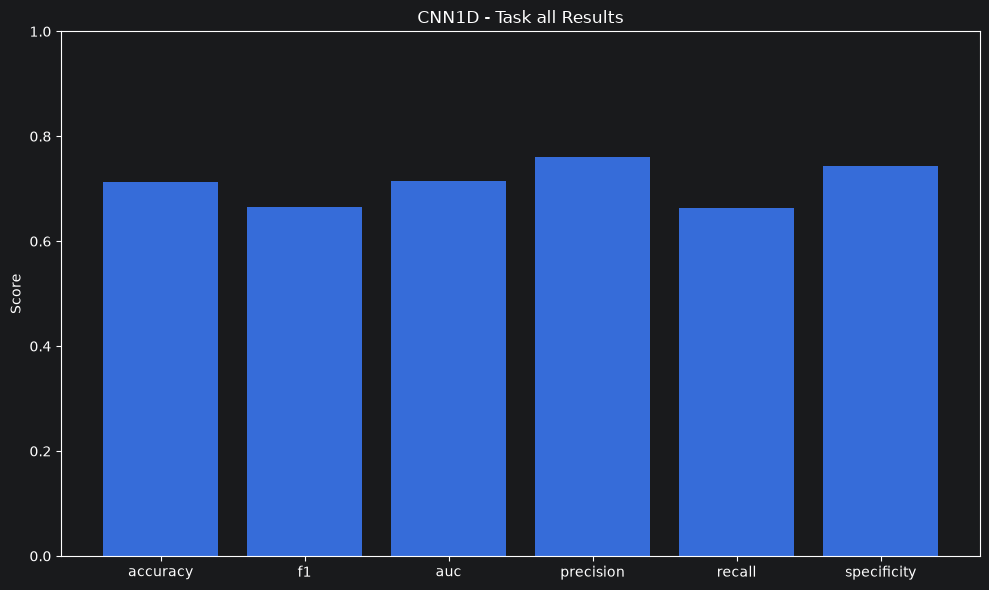

In [7]:
# =====================================
# RUN EXPERIMENT
# =====================================

runner = RunTimeSeriesCNN(
    data_root=_project_path("PaHaW/PaHaW/PaHaW_public"),
    metadata_path=_project_path("PaHaW/PaHaW/PaHaW_files/corpus_PaHaW.xlsx"),
    tasks=[4, 8],
    feature_names=("x", "y"),
    engineered_features=("speed", "pressure_derivative"),
    batch_size=16,
    epochs=200,
    learning_rate=1e-3,
    regularization=1e-6,
    n_splits=5,
    normalize=True,
    seed=42,
    device=("cuda" if torch.cuda.is_available() else "cpu"),
    output_dir=_project_path("experiments/cnn1D/timeseries + cnn/task_4_8/xy_speed_pressure_derivative"),
    training_cfg={
        "metrics": ["accuracy", "f1", "auc", "precision", "recall", "specificity"],
        "monitor_metric": "auc",
        "early_stopping_patience": 150,
        "min_delta": 1e-1,
        "results_writer": "csv",
        "save_metrics": True,
    },
)

summary = runner.run()

# =====================================
# RESULTS
# =====================================

averages = summary["averages"]

print("\n=== FINAL RESULTS ===")

print(f"Accuracy:    {averages['val_accuracy']:.4f}")
print(f"F1 Score:    {averages['val_f1']:.4f}")
print(f"AUC:         {averages['val_auc']:.4f}")
print(f"Precision:   {averages['val_precision']:.4f}")
print(f"Recall:      {averages['val_recall']:.4f}")
print(f"Specificity: {averages['val_specificity']:.4f}")

# =====================================
# BUILD DATAFRAME
# =====================================

df = pd.DataFrame([{
    "accuracy": averages["val_accuracy"],
    "f1": averages["val_f1"],
    "auc": averages["val_auc"],
    "precision": averages["val_precision"],
    "recall": averages["val_recall"],
    "specificity": averages["val_specificity"],
}])

# =====================================
# PLOT
# =====================================

metrics = [
    "accuracy",
    "f1",
    "auc",
    "precision",
    "recall",
    "specificity",
]

values = [
    averages[f"val_{m}"]
    for m in metrics
]

plt.figure(figsize=(10, 6))

plt.bar(
    metrics,
    values,
)

plt.ylim(0, 1)

plt.ylabel("Score")

plt.title(
    "CNN1D - Task all Results"
)

plt.tight_layout()

plt.show()
